# Dogs vs. cats image classification with EfficientNet-B0

This notebook documents the completed tutorial experiment. The official 25,000-image dataset was downloaded and partitioned deterministically into balanced training (17,500), validation (3,750), and held-out test (3,750) sets. Images are streamed progressively at 200×200 to keep memory bounded.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "requirements.txt").exists())
DATA = ROOT / "data/processed"
counts = {split: {label: len(list((DATA/split/label).glob("*.jpg"))) for label in ["cat", "dog"]} for split in ["train", "validation", "test"]}
display(pd.DataFrame(counts).T)

,cat,dog
train,8750,8750
validation,1875,1875
test,1875,1875


## Visual inspection

The first nine images of each class confirm the expected variation in pose, lighting, framing, image size, background, and number of animals. The data pipeline resizes every input to 200×200 while preserving progressive loading.

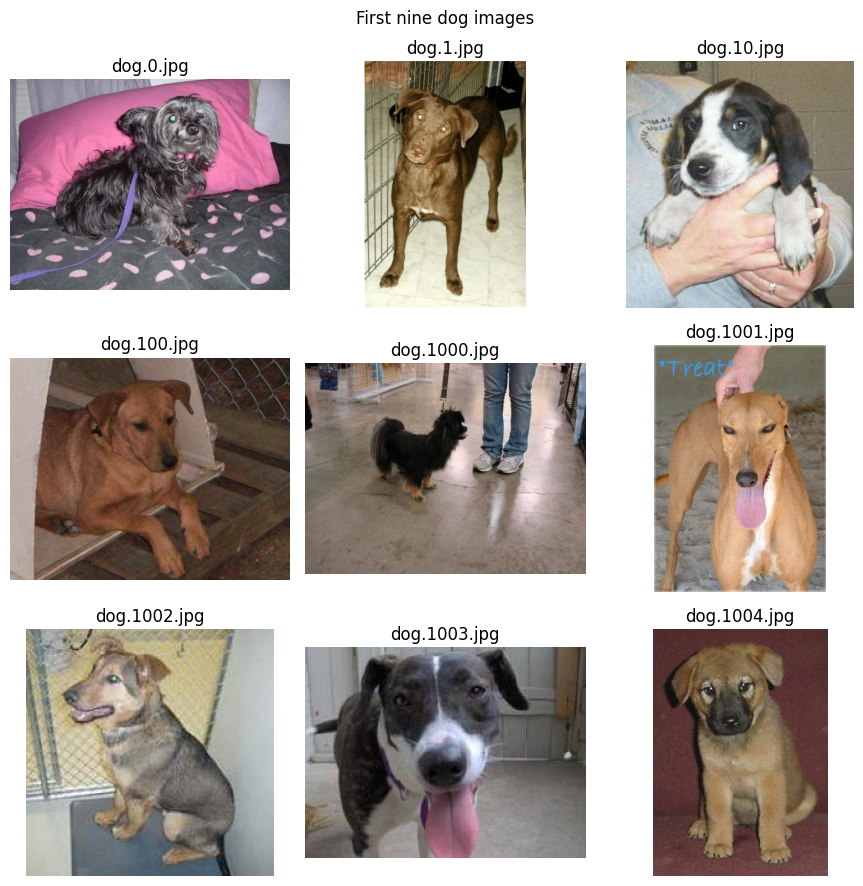

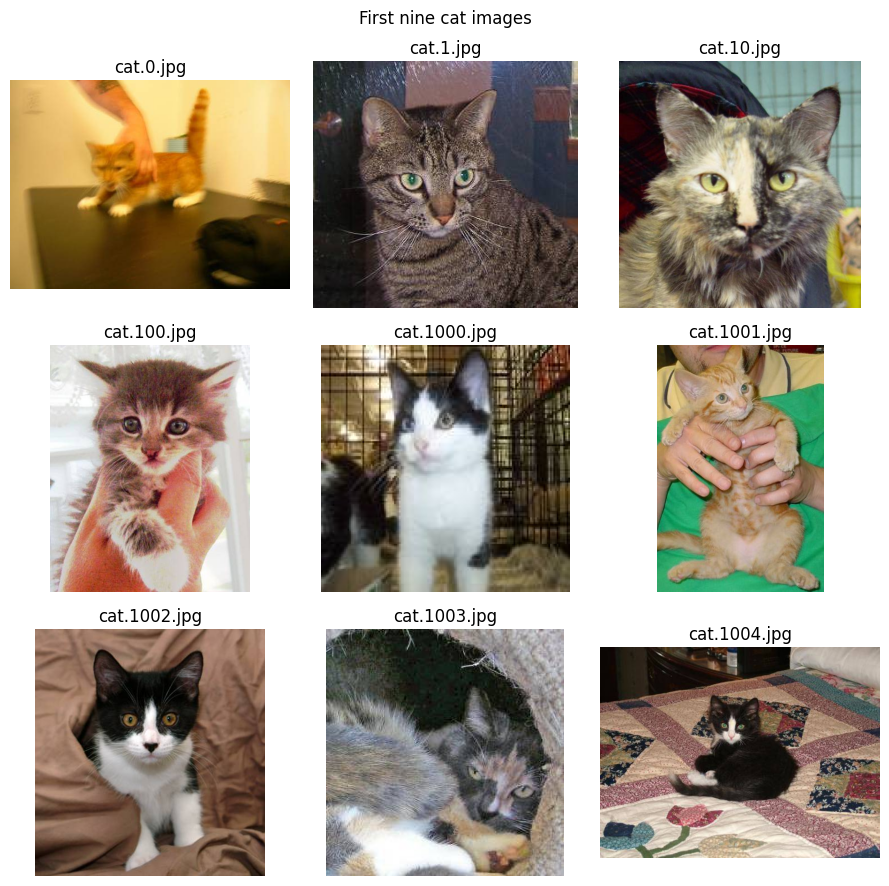

In [2]:
def show_first_nine(label):
    paths = sorted((DATA/"train"/label).glob("*.jpg"))[:9]
    fig, axes = plt.subplots(3, 3, figsize=(9, 9))
    for axis, path in zip(axes.flat, paths):
        axis.imshow(Image.open(path).convert("RGB"))
        axis.set_title(path.name)
        axis.axis("off")
    fig.suptitle(f"First nine {label} images")
    plt.tight_layout()
    plt.show()

show_first_nine("dog")
show_first_nine("cat")

## Architecture and optimization

`src/train.py` builds EfficientNet-B0 (`include_top=False`) with ImageNet weights, freezes the convolutional backbone, and adds augmentation, global average pooling, dropout, a 128-unit ReLU layer, and a two-class softmax head. Adam optimizes categorical cross-entropy. `ModelCheckpoint` retains the highest-validation-accuracy model and `EarlyStopping` restores the best validation-loss weights.

,accuracy,loss,val_accuracy,val_loss
0,0.9813,0.0488,0.9893,0.0278
1,0.9878,0.0322,0.9899,0.0300
2,0.9913,0.0243,0.9891,0.0319


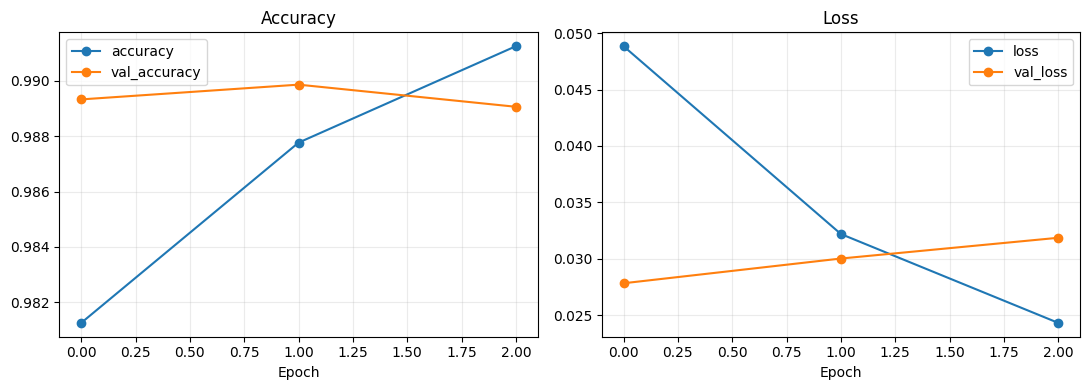

In [3]:
history = pd.read_csv(ROOT/"artifacts/history.csv")
display(history.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history[["accuracy", "val_accuracy"]].plot(ax=axes[0], marker="o", title="Accuracy")
history[["loss", "val_loss"]].plot(ax=axes[1], marker="o", title="Loss")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(alpha=.25)
plt.tight_layout()
plt.show()

Training stopped after three epochs because validation loss stopped improving. The best validation-accuracy checkpoint—not the last epoch—was reloaded for the held-out evaluation.

In [4]:
evaluation = json.loads((ROOT/"artifacts/evaluation.json").read_text())
print(f"Held-out test accuracy: {evaluation['test_accuracy']:.2%}")
print(f"Held-out test loss: {evaluation['test_loss']:.4f}")
display(pd.DataFrame(evaluation["classification_report"]).T.round(4))
matrix = pd.DataFrame(evaluation["confusion_matrix"], index=["actual cat", "actual dog"], columns=["predicted cat", "predicted dog"] )
display(matrix)

Held-out test accuracy: 98.91%
Held-out test loss: 0.0314


,precision,recall,f1-score,support
cat,0.9904,0.9877,0.9891,1875.0000
dog,0.9878,0.9904,0.9891,1875.0000
accuracy,0.9891,0.9891,0.9891,0.9891
macro avg,0.9891,0.9891,0.9891,3750.0000
weighted avg,0.9891,0.9891,0.9891,3750.0000


,predicted cat,predicted dog
actual cat,1852,23
actual dog,18,1857


## Saved-model prediction

The best checkpoint is saved locally in `models/efficientnet_b0_best.keras`. Model weights and the third-party image archive are intentionally Git-ignored as the tutorial recommends; the architecture, training code, history, and evaluation evidence are versioned.

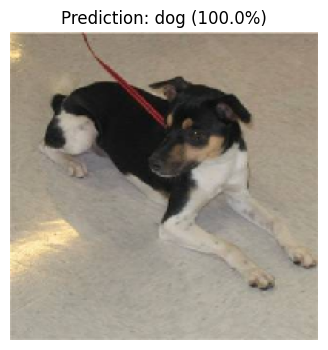

{'cat': np.float32(0.0), 'dog': np.float32(1.0)}


In [5]:
import numpy as np
from tensorflow import keras

model = keras.models.load_model(ROOT/"models/efficientnet_b0_best.keras")
sample_path = sorted((DATA/"test"/"dog").glob("*.jpg"))[0]
image = keras.utils.load_img(sample_path, target_size=(200, 200))
array = keras.utils.img_to_array(image)[None, ...]
probabilities = model.predict(array, verbose=0)[0]
predicted = ["cat", "dog"][int(np.argmax(probabilities))]
plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(f"Prediction: {predicted} ({probabilities.max():.1%})")
plt.axis("off")
plt.show()
print(dict(zip(["cat", "dog"], probabilities.round(4))))

## Conclusion

The best EfficientNet-B0 checkpoint achieved **98.91% accuracy** on 3,750 held-out images: 23 cats were labeled as dogs and 18 dogs as cats. Balanced precision and recall near 0.99 indicate that the aggregate result is not hiding a class-specific failure. Remaining errors should be reviewed for ambiguous framing, multiple animals, and occlusion before deployment.